In [1]:
from helper_functions.get_data_dictionary_target_X_y_imports import *

Loaded: 
      data: the entire dataset.
      dictionary: the data dictionary.
      X: the features columns with 'inhospital_mortality', 'studyid_adm', 'lengthadm' dropped.
      y: the target column.


In [2]:
special_features = dictionary[
    dictionary.Feature.str.startswith('cookfuel_adm')].Feature.tolist()
df = data[special_features + [target]]

In [3]:
df.cookfuel_adm___1.value_counts()


cookfuel_adm___1
Checked      1312
Unchecked     836
Name: count, dtype: int64

In [4]:
for col in special_features:
    df[col] = np.where(df[col]=='Checked', 1, 0)

df.cookfuel_adm___1.value_counts()


cookfuel_adm___1
1    1312
0     836
Name: count, dtype: int64

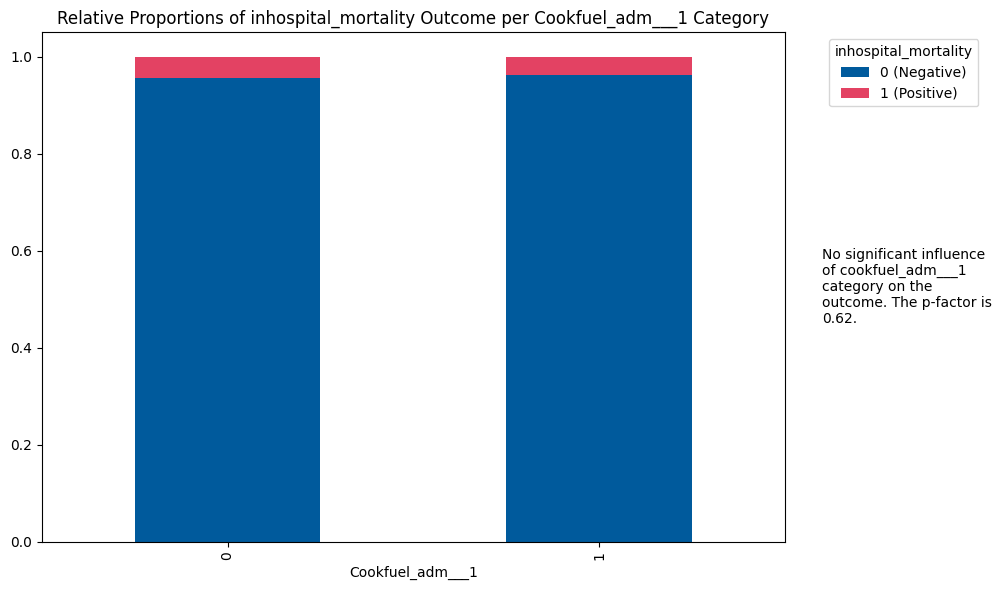

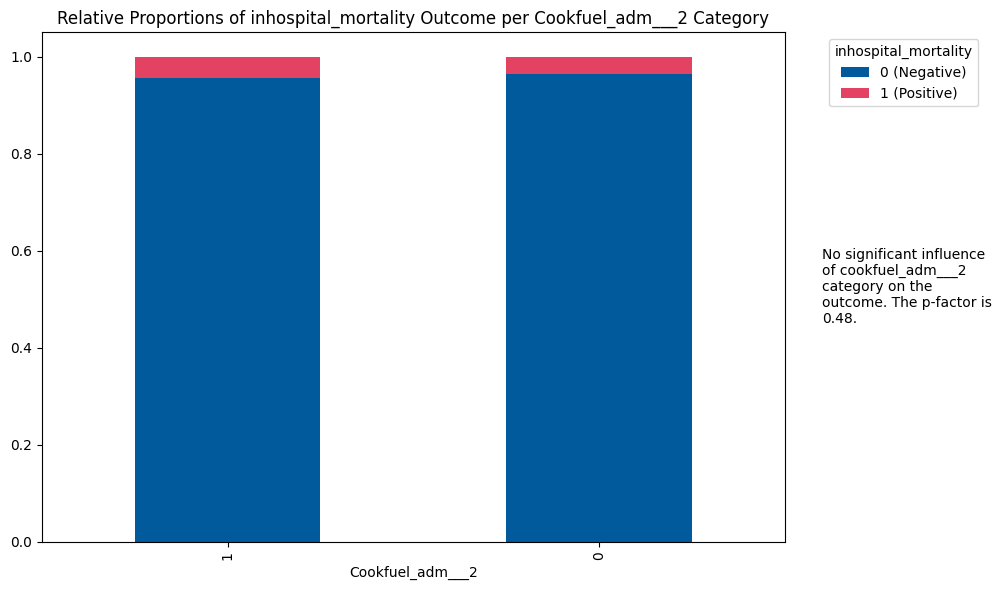

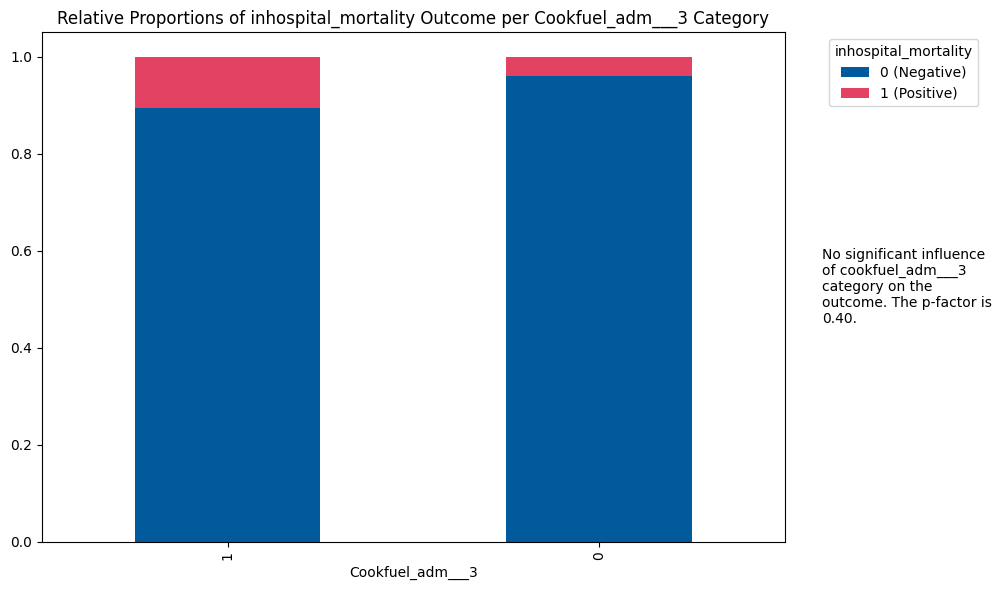

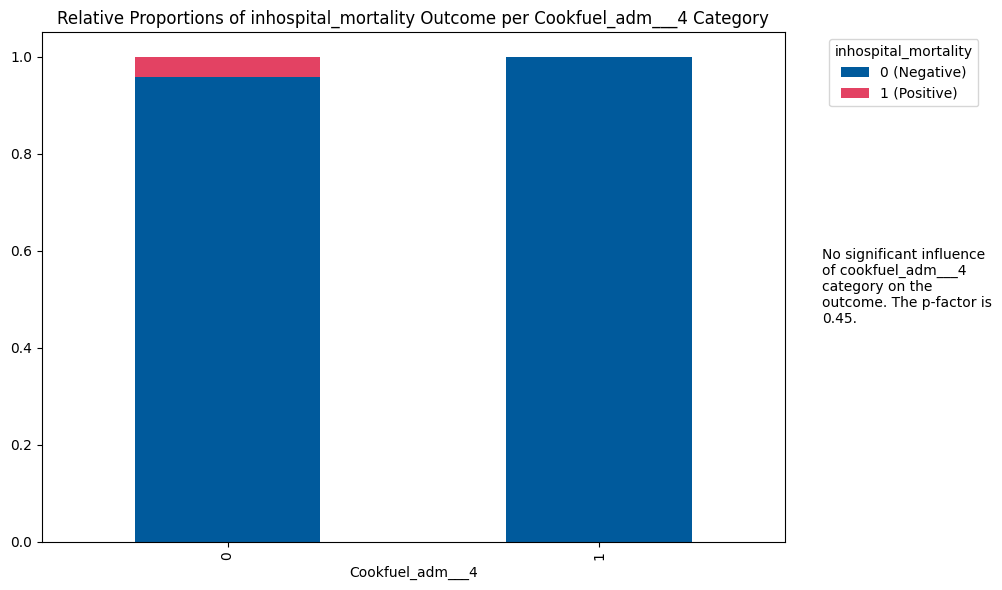

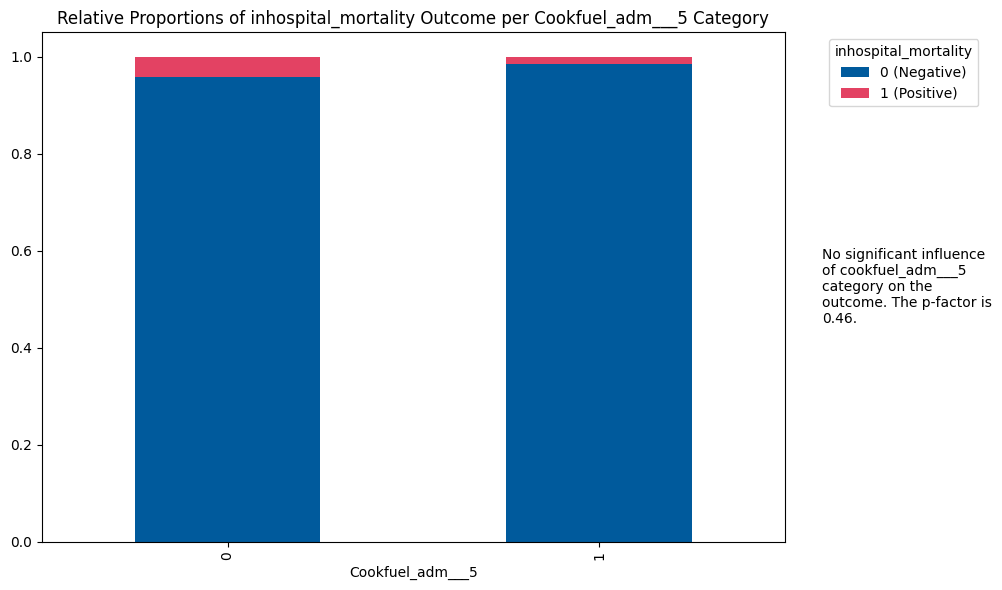

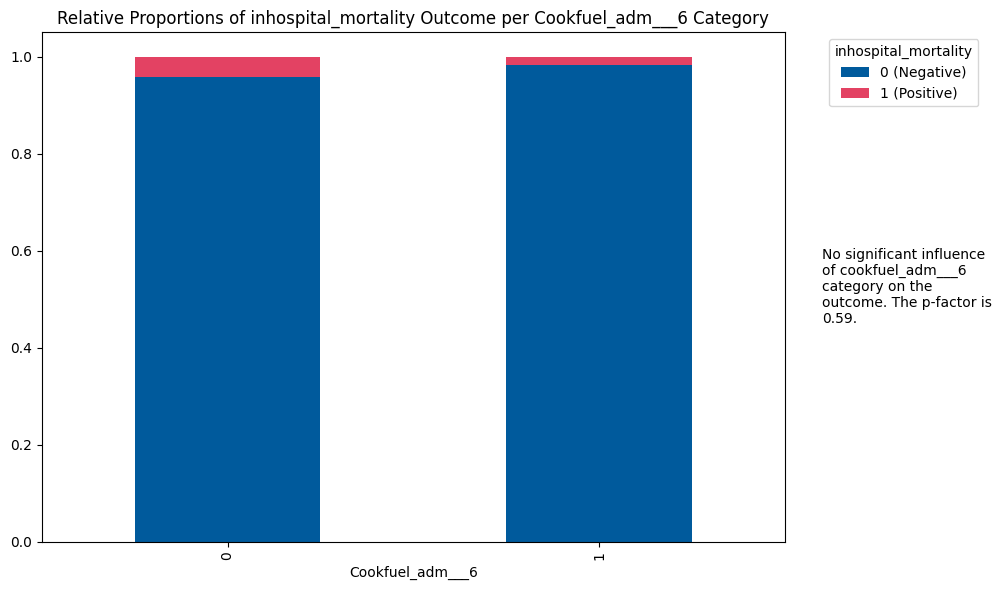

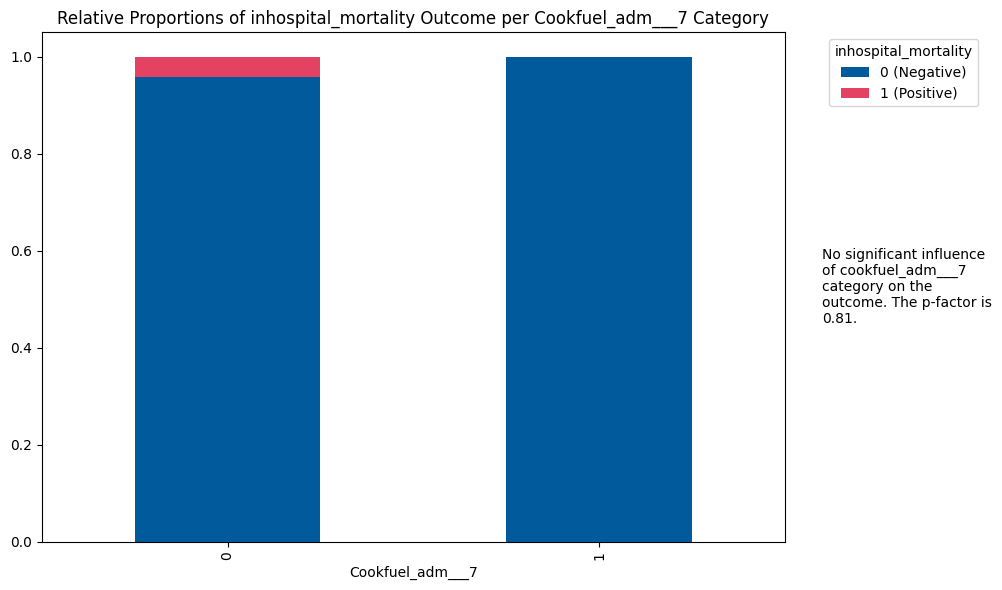

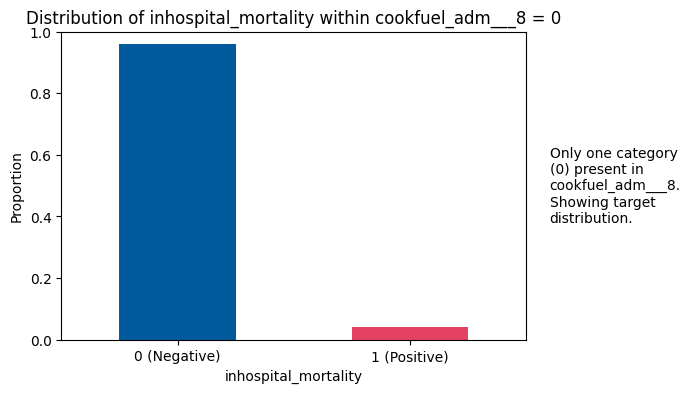

In [5]:
for col in special_features:
    try:
        categorical_analysis(col, df, target, color=['#005A9C', '#E34263'])
    except Exception as e:
        print(col)
        print(e)

In [6]:
import itertools
from tqdm.notebook import tqdm
import math
import time

results = {}

for k in tqdm(range(1, len(special_features)+1)):  # Looping from K = 1 to len(special_features)
    feature_combinations = itertools.combinations(special_features, k)
    num_combinations = math.comb(len(special_features), k)
    
    combined_features = {
        "_".join(cols): sum(df[col] for col in cols)
        for cols in feature_combinations
    }
    
    for feature_name, feature_values in tqdm(combined_features.items(), total=num_combinations, leave=False):
        tmp = feature_values.copy()
        tmp.name = feature_name
        tmp = tmp.to_frame()
        tmp[target] = df[target]
        
        result = categorical_analysis(feature_name, tmp, target, 
                                      return_result_only=True)
        
        results[feature_name] = result

for k, v in results.items():
    if v and v > 0.3:
        print(k, v)


  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

  0%|          | 0/56 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
for k, v in results.items():
    if v:
        print(k, v)

## `cookloc_adm`

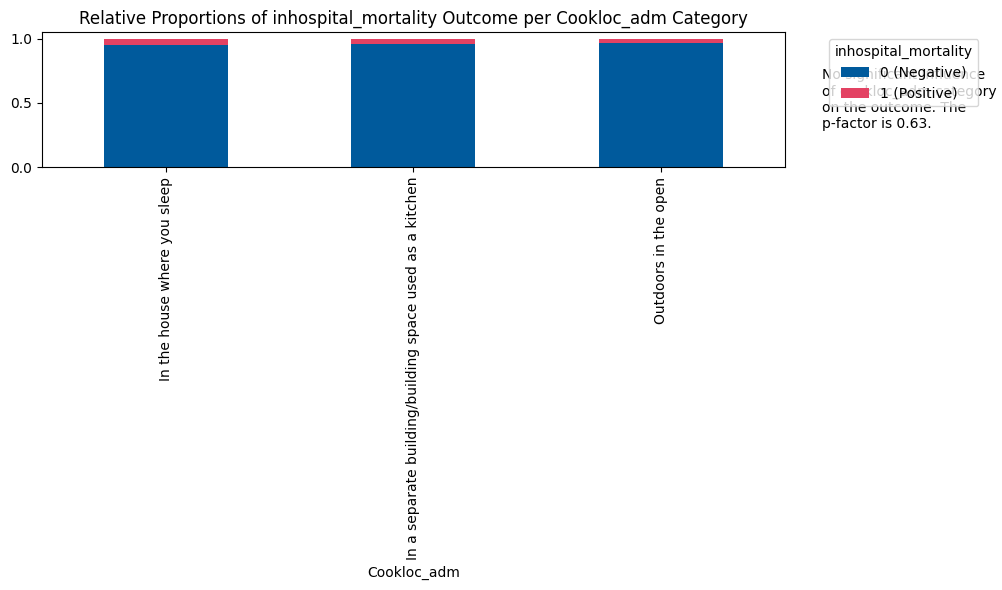

In [9]:
categorical_analysis("cookloc_adm", data, target, color=['#005A9C', '#E34263'])

In [11]:
data[data["cookloc_adm"].isna()][special_features]

,cookfuel_adm___1,cookfuel_adm___2,cookfuel_adm___3,cookfuel_adm___4,cookfuel_adm___5,cookfuel_adm___6,cookfuel_adm___7,cookfuel_adm___8
39,Checked,Unchecked,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked


## `lightfuel_adm`

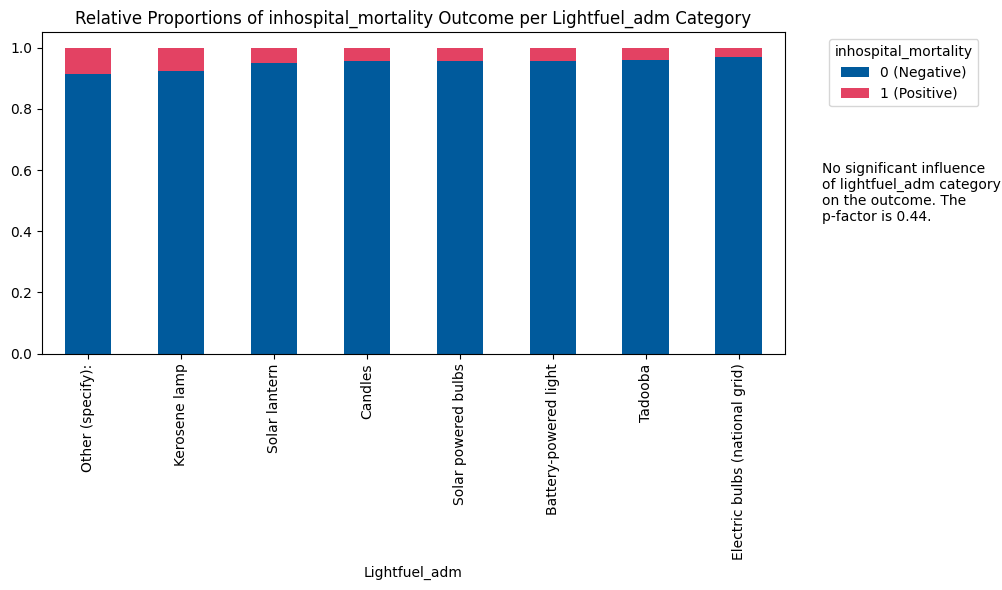

In [20]:
categorical_analysis("lightfuel_adm", data, target, color=['#005A9C', '#E34263'])

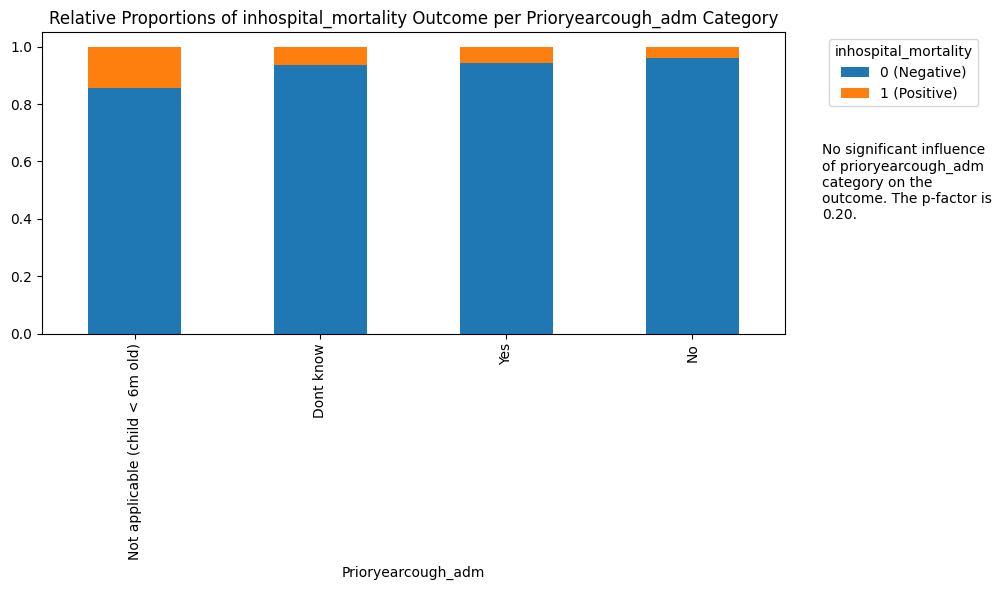

In [31]:
categorical_analysis("prioryearcough_adm", data, target)

In [38]:
data.prioryearcough_adm.value_counts()


prioryearcough_adm
No                                 1852
Yes                                 273
Dont know                            16
Not applicable (child < 6m old)       7
Name: count, dtype: int64

In [39]:
data[data.prioryearcough_adm=='Not applicable (child < 6m old)'].agecalc_adm


234      9.5
472     34.4
998     19.9
1002    31.8
1814    11.2
1829    20.5
1975     6.4
Name: agecalc_adm, dtype: float64